# THERMOSCOPE · 02 Results
Reads the evidence files in `outputs/`.

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
R = json.load(open('../outputs/metrics_regression.json')); C = json.load(open('../outputs/metrics_classification.json'))
P = pd.read_csv('../outputs/predictions_test.csv'); json.load(open('../outputs/splits.json'))

{'seed': 20261115, 'design': 'GroupShuffleSplit(test_size=0.2) by fluid; GroupKFold(5) inside training fluids', 'test_fluids': ['Methane', 'n-Hexane', 'Ethylene', 'Water', 'Hydrogen sulfide'], 'folds': {'1': ['Propylene', 'Nitrogen', 'Carbon dioxide', 'R-134a'], '2': ['Propane', 'Oxygen', 'Argon', 'Sulfur dioxide'], '3': ['n-Heptane', 'n-Octane', 'Carbon monoxide'], '4': ['Isobutane', 'n-Pentane', 'Benzene'], '5': ['Ethane', 'n-Butane', 'Ammonia']}}

## Degree selection (grouped CV, Z)

In [2]:
pd.DataFrame(R['degree_selection'])

,deg,p,ols,ridge,ridgeLam,lasso,lassoAlpha
0,1,3,0.220920,0.220920,0.000001,NaN,NaN
1,2,9,0.182045,0.182045,0.000001,NaN,NaN
2,3,19,0.152141,0.152138,0.010000,NaN,NaN
3,4,34,0.135271,0.135240,0.001000,NaN,NaN
4,5,55,0.121112,0.121109,0.000010,0.140935,0.000046


## Regression: grouped-CV and test performance

In [3]:
rows = [dict(target=t, model=k, cv_rmse=v.get('cv'), **v['test']) for t, T in R['targets'].items() for k, v in T.items()]
pd.DataFrame(rows).set_index(['target', 'model']).round(4)

cv_rmse    rmse     mae      r2
target model                                  
Z      base     0.3477  0.3466  0.2986 -0.0004
       linear   0.2209  0.2237  0.1760  0.5833
       ols      0.1211  0.1249  0.0795  0.8701
       ridge    0.1211  0.1249  0.0795  0.8701
       lasso    0.1409  0.1433  0.0963  0.8290
ar     base     1.4768  1.4501  1.1601 -0.0005
       linear   0.9824  0.9808  0.7864  0.5423
       ols      0.4075  0.4273  0.2527  0.9131
       ridge    0.4075  0.4273  0.2529  0.9131
       lasso    0.4753  0.4902  0.3080  0.8857
hr     base     3.3807  3.3063  2.7098 -0.0009
       linear   2.1988  2.1836  1.7613  0.5634
       ols      0.9962  1.0167  0.6201  0.9054
       ridge    0.9961  1.0166  0.6196  0.9054
       lasso    1.1415  1.1443  0.7351  0.8801
sr     base     1.5931  1.5503  1.2616 -0.0015
       linear   1.0416  1.0271  0.8243  0.5604
       ols      0.4759  0.4743  0.2921  0.9063
       ridge    0.4759  0.4743  0.2919  0.9063
       lasso    0.5410  0.5294  0.3417  0.8832
gr     base     1.8017  1.7749  1.4498 -0.0005
       linear   1.1718  1.1756  0.9446  0.5610
       ols      0.5247  0.5486  0.3293  0.9044
       ridge    0.5246  0.5486  0.3295  0.9044
       lasso    0.6074  0.6233  0.3968  0.8766
lnphi  base     0.8940  0.8421  0.6008 -0.0019
       linear   0.5948  0.5660  0.4319  0.5473
       ols      0.0931  0.0909  0.0593  0.9883
       ridge    0.0931  0.0909  0.0593  0.9883
       lasso    0.1637  0.1647  0.1133  0.9617

## Actual versus predicted and residuals (Ridge, Z)

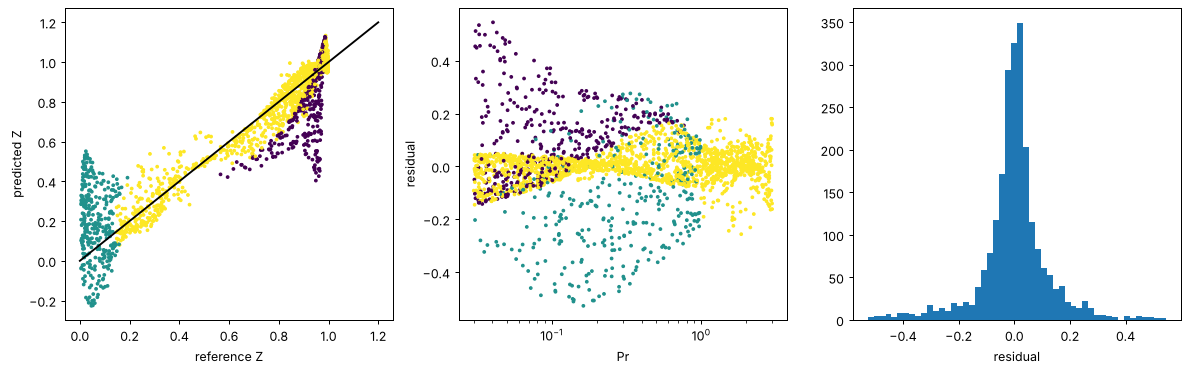

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(P.Z, P.pred_Z_ridge, c=P.phase, s=4); ax[0].plot([0, 1.2], [0, 1.2], 'k'); ax[0].set_xlabel('reference Z'); ax[0].set_ylabel('predicted Z')
ax[1].scatter(P.Pr, P.Z - P.pred_Z_ridge, c=P.phase, s=4); ax[1].set_xscale('log'); ax[1].set_xlabel('Pr'); ax[1].set_ylabel('residual')
ax[2].hist(P.Z - P.pred_Z_ridge, bins=50); ax[2].set_xlabel('residual')

## Per-fluid error

In [5]:
P.assign(e=(P.Z - P.pred_Z_ridge) ** 2).groupby('fluid').e.mean().pow(0.5).rename('RMSE Z (ridge)')

fluid
Ethylene            0.119245
Hydrogen sulfide    0.124456
Methane             0.130998
Water               0.119175
n-Hexane            0.129969
Name: RMSE Z (ridge), dtype: float64

## Classification

In [6]:
for k in ('majority', 'lr', 'svm'):
    print(k, {m: round(C[k]['test'][m], 4) for m in ('acc', 'macroF1', 'balAcc')}); print(np.array(C[k]['test']['cm']))

majority {'acc': 0.6994, 'macroF1': 0.2744, 'balAcc': 0.3333}
[[   0    0  361]
 [   0    0  344]
 [   0    0 1640]]
lr {'acc': 0.8832, 'macroF1': 0.8371, 'balAcc': 0.8315}
[[ 283    2   76]
 [   8  270   66]
 [  53   69 1518]]
svm {'acc': 0.9979, 'macroF1': 0.9971, 'balAcc': 0.9967}
[[ 361    0    0]
 [   0  341    3]
 [   0    2 1638]]


## Hyper-parameter search

In [7]:
cv = pd.read_csv('../outputs/cv_classification.csv'); cv[cv.model == 'svm_rbf'].pivot(index='C', columns='gamma', values='cv_macro_f1').round(4)

gamma,0.1,0.3,1.0,3.0,10.0
C,,,,,
1.0,0.9467,0.9589,0.9580,0.9377,0.8900
10.0,0.9647,0.9701,0.9618,0.9447,0.8997
100.0,0.9792,0.9788,0.9623,0.9430,0.8962
1000.0,0.9839,0.9819,0.9608,0.9440,0.8969


In [8]:
cr = pd.read_csv('../outputs/cv_regression.csv'); cr[(cr.target == 'Z') & (cr.model == 'ridge')].drop_duplicates(['penalty', 'degree']).pivot(index='penalty', columns='degree', values='cv_rmse').round(4)

degree,1,2,3,4,5
penalty,,,,,
0.000001,0.2209,0.1820,0.1521,0.1353,0.1211
0.000003,0.2209,0.1820,0.1521,0.1353,0.1211
0.000010,0.2209,0.1820,0.1521,0.1353,0.1211
0.000032,0.2209,0.1820,0.1521,0.1353,0.1211
0.000100,0.2209,0.1820,0.1521,0.1353,0.1212
0.000316,0.2209,0.1820,0.1521,0.1353,0.1217
0.001000,0.2209,0.1820,0.1521,0.1352,0.1229
0.003162,0.2209,0.1820,0.1521,0.1352,0.1248
0.010000,0.2209,0.1820,0.1521,0.1356,0.1283


## Gram matrix diagnostics and ablations

In [9]:
pd.read_csv('../outputs/gram_diagnostics.csv')

,degree,scaling,p,sigma_max,sigma_min,cond_X,cond_G,rank
0,1,standardised,3,90.284075,88.312047,1.022330e+00,1.045159e+00,3
1,1,raw_with_intercept,4,150.545051,9.881932,1.523437e+01,2.320862e+02,4
2,2,standardised,9,172.096480,7.230191,2.380248e+01,5.665581e+02,9
3,2,raw_with_intercept,10,262.423650,1.106797,2.371018e+02,5.621726e+04,10
4,3,standardised,19,264.417621,0.631080,4.189921e+02,1.755543e+05,19
5,3,raw_with_intercept,20,582.271788,0.094113,6.186927e+03,3.827807e+07,20
6,4,standardised,34,365.185174,0.058599,6.231947e+03,3.883717e+07,34
7,4,raw_with_intercept,35,1463.729820,0.009264,1.579937e+05,2.496200e+10,35
8,5,standardised,55,473.590886,0.005538,8.551833e+04,7.313384e+09,55
9,5,raw_with_intercept,56,3862.731450,0.000894,4.321403e+06,1.867453e+13,56


In [10]:
json.load(open('../outputs/ablations.json'))

{'cv_grouped_vs_rowwise': {'group': 0.1211091549126329, 'random': 0.12095816351061803}, 'rowwise_secondary': {'ridge_Z': {'rmse': 0.12607869846049435, 'mae': 0.08068763641475199, 'r2': 0.8683925169856216}, 'svm_macroF1': 0.9913243828374214, 'n_test': 2062}, 'omega_extrapolation': {'threshold': 0.25, 'n_train': 5152, 'n_eval': 2811, 'ridge_Z': {'rmse': 0.5915938224088919, 'mae': 0.30430288002039946, 'r2': -1.7140365907176962}, 'svm_macroF1': 0.893729285367265}, 'guard_band': [{'guard': 0.0, 'rows': 10340, 'rejected': 0, 'svm': 0.987139574291111, 'lr': 0.8194453036909934}, {'guard': 0.02, 'rows': 10308, 'rejected': 32, 'svm': 0.9839348640270618, 'lr': 0.8240020913049193}, {'guard': 0.05, 'rows': 10263, 'rejected': 77, 'svm': 0.9904769865704315, 'lr': 0.8255487769868131}]}